# Výhody a nevýhody metody Slice Sampling v bayesovské inverzi

V bayesovské inverzi se ke generování vzorků z výsledného rozdělení pravděpodobnosti nejčastěji používají metody založené na algoritmu **Metropolis-Hastings** (MH). Tato práce bude zkoumat **slice sampling** jako alternativu, která může být v některých situacích robustnější a snáze nastavitelná.

## Předběžná osnova práce

**Teoretická část:**
1. Bayesovská inverze (stačí stručně — jako motivace proč vzorkovat)
2. Metoda Metropolis-Hastings (stačí stručně — bude použita pro porovnání)
3. Metoda Slice Sampling (detailně — princip, varianty, vlastnosti)

**Praktická část:**
1. Implementace obou metod
2. Soubor testovacích úloh (různé tvary rozdělení, různé dimenze)
3. Srovnání na testovacích úlohách (robustnost, efektivita, ladění parametrů)
4. Zhodnocení — kdy se vyplatí použít slice sampling místo MH

In [1]:
import importlib, samplers
importlib.reload(samplers)

import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.stats import norm
from samplers import slice_sampling, slice_sampling_one_step, metropolis_hastings

## Ukázka vzorkování z 1d rozdělení pravděpodobnosti

Jako cílové rozdělení použijeme směs dvou normálních rozdělení s následující hustotou pravděpodobnosti:

$$p(x) = 0{,}3 \cdot \mathcal{N}(x;\,-2,\,1) \;+\; 0{,}7 \cdot \mathcal{N}(x;\,2,\,0{,}7)$$

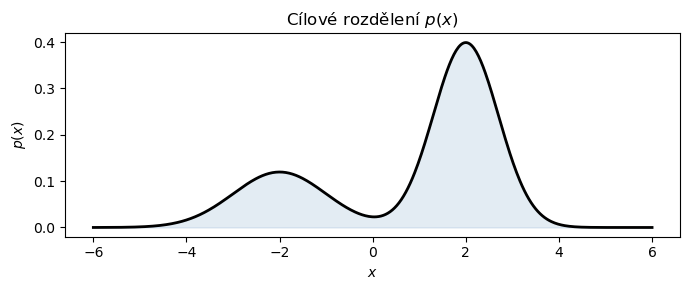

In [ ]:
# --- Cílové rozdělení ---
def target_pdf(x):
    return 0.3 * norm.pdf(x, -2, 1) + 0.7 * norm.pdf(x, 2, 0.7)

def log_target_pdf(x):
    p = target_pdf(x)in the grf_playground, create a report on this question: Can the nonstationary grf from the ipynb be obtained as a transformation of a stationary grf? Start with good mathematical description of the setting
    return np.log(p) if p > 0 else -np.inf

# Vizualizace
x_grid = np.linspace(-6, 6, 500)in the grf_playground, create a report on this question: Can the nonstationary grf from the ipynb be obtained as a transformation of a stationary grf? Start with good mathematical description of the setting
plt.figure(figsize=(7, 3))
plt.plot(x_grid, target_pdf(x_grid), 'k-', lw=2)
plt.fill_between(x_grid, target_pdf(x_grid), alpha=0.15, color='steelblue')
plt.title("Cílové rozdělení $p(x)$")
plt.xlabel("$x$"); plt.ylabel("$p(x)$")
plt.tight_layout(); plt.show()

## Metropolis-Hastings (běžně používaná metoda)

Random Walk MH v každém kroku:
1. Navrhne $x' = x + \varepsilon$, kde $\varepsilon \sim \mathcal{N}(0, \sigma^2)$.
2. Spočte pravděpodobnost přijetí $\alpha = \min\!\big(1,\; p(x')/p(x)\big)$.
3. S pravděpodobností $\alpha$ přijme $x'$, jinak zůstane v $x$.

Klíčový **problém**: výkon silně závisí na volbě $\sigma$.
- **Příliš malé $\sigma$** → téměř vše přijato, ale kroky jsou tak malé, že řetězci trvá příliš dlouho projít celý pravděpodobnostní prostor, např. se může "zaseknout" v okolí jednoho módu.
- **Příliš velké $\sigma$** → dělá příliš velké kroky, a proto je většina návrhů zamítnuta a opět řetězci trvá příliš dlouho projít celý pravděpodobnostní prostor.

σ =   0.1 | accept = 96% | vyhodnocení f(x): 10,001 | čas: 1.648 s
σ =   2.0 | accept = 50% | vyhodnocení f(x): 10,001 | čas: 1.828 s
σ =  40.0 | accept = 4% | vyhodnocení f(x): 10,001 | čas: 1.932 s


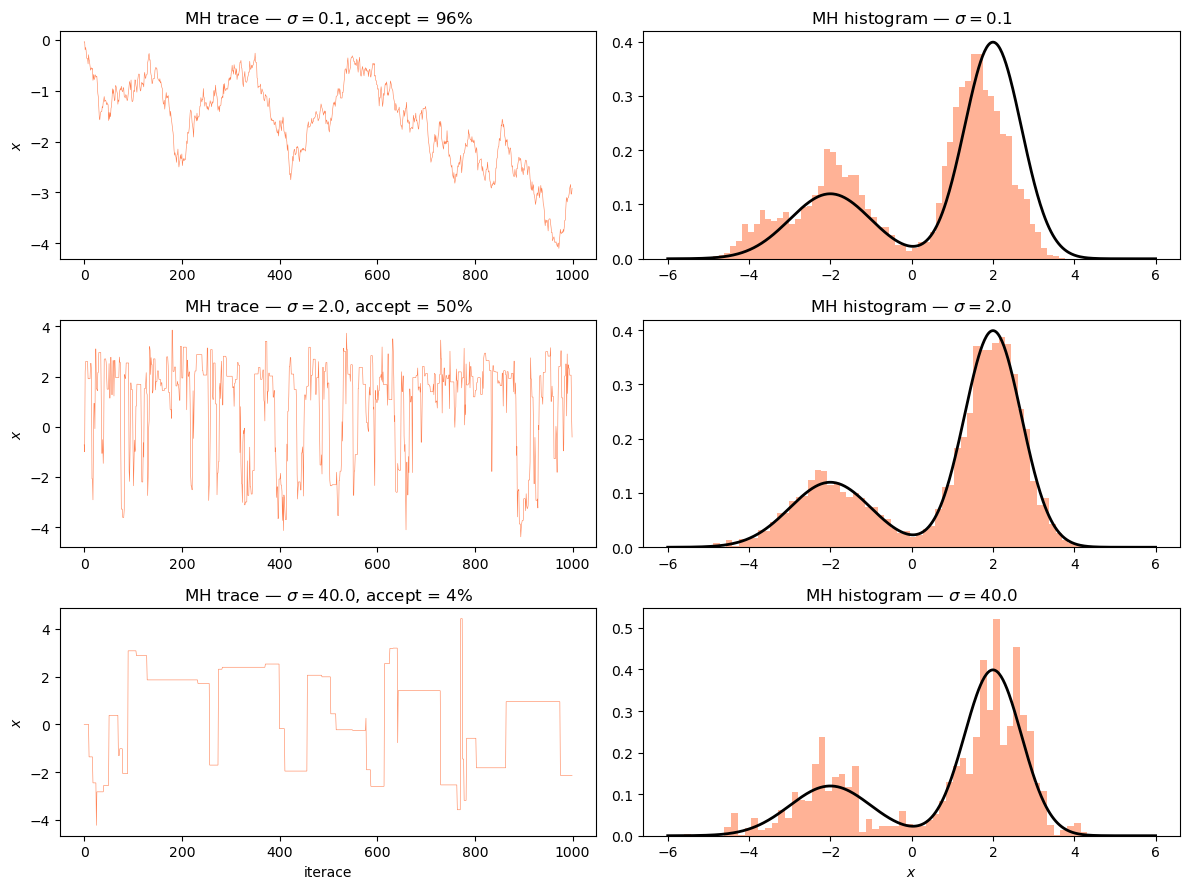

In [3]:
N = 10_000  # počet vzorků

# --- MH se třemi různými hodnotami σ ---
sigmas = [0.1, 2.0, 40.0]
fig, axes = plt.subplots(len(sigmas), 2, figsize=(12, 3 * len(sigmas)))

for i, sigma in enumerate(sigmas):
    start_time = time.time()
    samples_mh, acc, n_evals_mh = metropolis_hastings(log_target_pdf, x0=0.0, n_samples=N, proposal_std=sigma)
    elapsed = time.time() - start_time
    print(f"σ = {sigma:5.1f} | accept = {acc:.0%} | vyhodnocení f(x): {n_evals_mh:,} | čas: {elapsed:.3f} s")

    # Trace plot
    axes[i, 0].plot(samples_mh[:1000], lw=0.4, color='coral')
    axes[i, 0].set_ylabel("$x$")
    axes[i, 0].set_title(f"MH trace — $\\sigma={sigma}$, accept = {acc:.0%}")

    # Histogram (bez burn-in)
    axes[i, 1].hist(samples_mh[1000:], bins=60, density=True, alpha=0.6, color='coral')
    axes[i, 1].plot(x_grid, target_pdf(x_grid), 'k-', lw=2)
    axes[i, 1].set_title(f"MH histogram — $\\sigma={sigma}$")

axes[-1, 0].set_xlabel("iterace"); axes[-1, 1].set_xlabel("$x$")
plt.tight_layout(); plt.show()

## Slice Sampling (alternativa)

Slice sampling nabízí jiný přístup: místo navrhování bodů a jejich přijímání/zamítání **přímo vzorkuje z oblasti pod grafem** hustoty.

Každý krok je rozdělený na 2 části:
1. **Vertikální:** Vybereme $y \sim \text{Uniform}(0, f(x))$ — náhodnou výšku pod křivkou.
2. **Horizontální:** Najdeme *řez* $S = \{x' : f(x') > y\}$ a vybereme $x'$ rovnoměrně z $S$.

Klíčový rozdíl: nepočítá se žádná pravděpodobnost přijetí, každý vzorek je přijat. Sampler se automaticky přizpůsobuje tvaru rozdělení — když je hustota úzká/široká, řez $S$ je automaticky úzký/široký, takže velikost kroku odpovídá lokálnímu tvaru bez nutnosti ručního ladění.

**Poznámka k řezu $S$:** Řez $S$ je definován jako *celá* množina bodů, kde $f(x') > y$. U multimodálního rozdělení může $S$ sestávat z několika disjunktních intervalů. V *ideálním* případě vzorkujeme ze všech těchto intervalů. V praxi (stepping-out varianta) ale hledáme hranice řezu rozšiřováním okna z aktuálního bodu, takže odlehlé intervaly mohou zůstat mimo nalezené okno. To může mírně zpomalit přechody mezi vzdálenými módy, ale **nenarušuje korektnost** algoritmu — stále vzorkujeme z podmnožiny $S$ a detailní rovnováha je zachována.

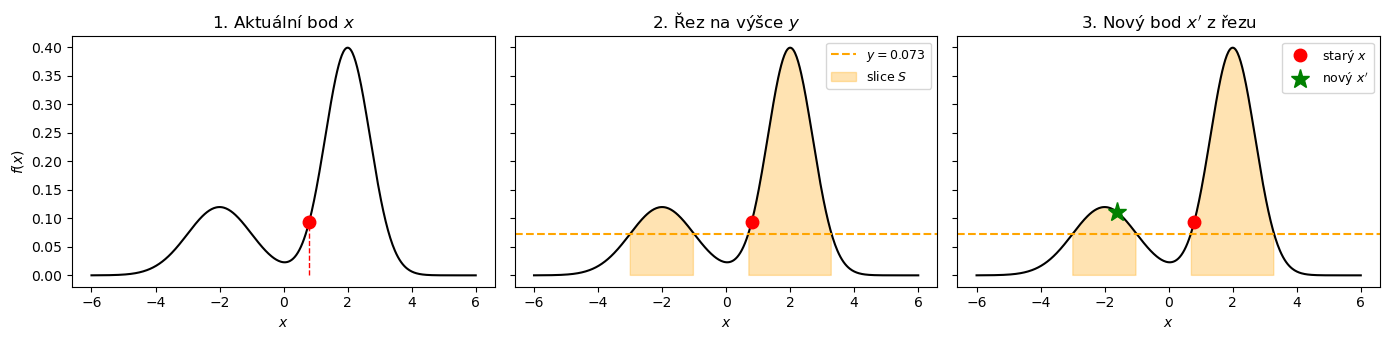

In [4]:
# --- Ilustrace jednoho kroku slice samplingu ---
rng = np.random.default_rng(42)
x_curr = 0.8
f_curr = target_pdf(x_curr)
y_slice = rng.uniform(0, f_curr)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharex=True, sharey=True)
for ax in axes:
    ax.plot(x_grid, target_pdf(x_grid), 'k-', lw=1.5)
    ax.set_xlabel("$x$")

# 1) Aktuální bod
axes[0].plot(x_curr, f_curr, 'ro', ms=9, zorder=5)
axes[0].vlines(x_curr, 0, f_curr, colors='r', ls='--', lw=1)
axes[0].set_title("1. Aktuální bod $x$")
axes[0].set_ylabel("$f(x)$")

# 2) Řez (slice)
axes[1].plot(x_curr, f_curr, 'ro', ms=9, zorder=5)
axes[1].axhline(y_slice, color='orange', ls='--', lw=1.5, label=f"$y = {y_slice:.3f}$")
axes[1].fill_between(x_grid, 0, target_pdf(x_grid),
                     where=target_pdf(x_grid) > y_slice,
                     alpha=0.3, color='orange', label="slice $S$")
axes[1].legend(fontsize=9)
axes[1].set_title("2. Řez na výšce $y$")

# 3) Nový bod
x_new = -1.6
axes[2].axhline(y_slice, color='orange', ls='--', lw=1.5)
axes[2].fill_between(x_grid, 0, target_pdf(x_grid),
                     where=target_pdf(x_grid) > y_slice,
                     alpha=0.3, color='orange')
axes[2].plot(x_curr, f_curr, 'ro', ms=9, zorder=5, label="starý $x$")
axes[2].plot(x_new, target_pdf(x_new), 'g*', ms=14, zorder=5, label="nový $x'$")
axes[2].legend(fontsize=9)
axes[2].set_title("3. Nový bod $x'$ z řezu")

plt.tight_layout(); plt.show()

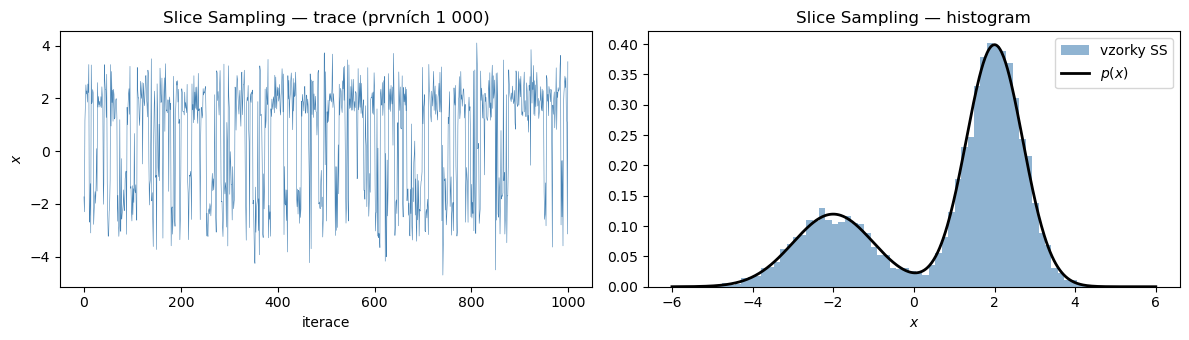

In [8]:
# --- Slice Sampling: trace, histogram ---
samples_ss, n_evals_ss = slice_sampling(log_target_pdf, x0=0.0, n_samples=N, w=2.0)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

axes[0].plot(samples_ss[:1000], lw=0.4, color='steelblue')
axes[0].set_title("Slice Sampling — trace (prvních 1 000)")
axes[0].set_xlabel("iterace"); axes[0].set_ylabel("$x$")

axes[1].hist(samples_ss[1000:], bins=60, density=True, alpha=0.6, color='steelblue', label="vzorky SS")
axes[1].plot(x_grid, target_pdf(x_grid), 'k-', lw=2, label="$p(x)$")
axes[1].set_title("Slice Sampling — histogram")
axes[1].legend(); axes[1].set_xlabel("$x$")

plt.tight_layout(); plt.show()

### Volba šířky okna $w$

Slice sampling sice nemá akceptační krok, ale má parametr **$w$** (šířka okna pro stepping-out).
- **Příliš malé $w$**: stepping-out potřebuje mnoho kroků k nalezení hranic řezu → zbytečně mnoho vyhodnocení $f(x)$.
- **Příliš velké $w$**: okno příliš přesahuje řez, shrinking ho následně zúží → mírně neefektivní, ale výsledek je stále korektní.

Na rozdíl od $\sigma$ u MH, špatná volba $w$ ovlivňuje pouze **rychlost** vzorkování (více vyhodnocení $f$), ne **kvalitu** vzorků — řetězec stále generuje vzorky z korektního rozdělení. To je dáno tím, že stepping-out/shrinking vždy najde správné hranice řezu bez ohledu na počáteční $w$; šířka okna ovlivňuje jen to, kolik kroků k tomu potřebuje.

**Burn-in:** Slice sampling, stejně jako MH, má burn-in periodu — počáteční vzorky jsou ovlivněny volbou startovního bodu $x_0$, a proto je zahazujeme. Burn-in u slice samplingu bývá typicky kratší, protože řetězec se pohybuje efektivněji (nejsou zamítané kroky).

w =   0.1 | vyhodnocení f(x): 370,080 | čas: 62.958 s
w =   2.0 | vyhodnocení f(x): 65,931 | čas: 9.822 s
w =  40.0 | vyhodnocení f(x): 77,647 | čas: 13.629 s


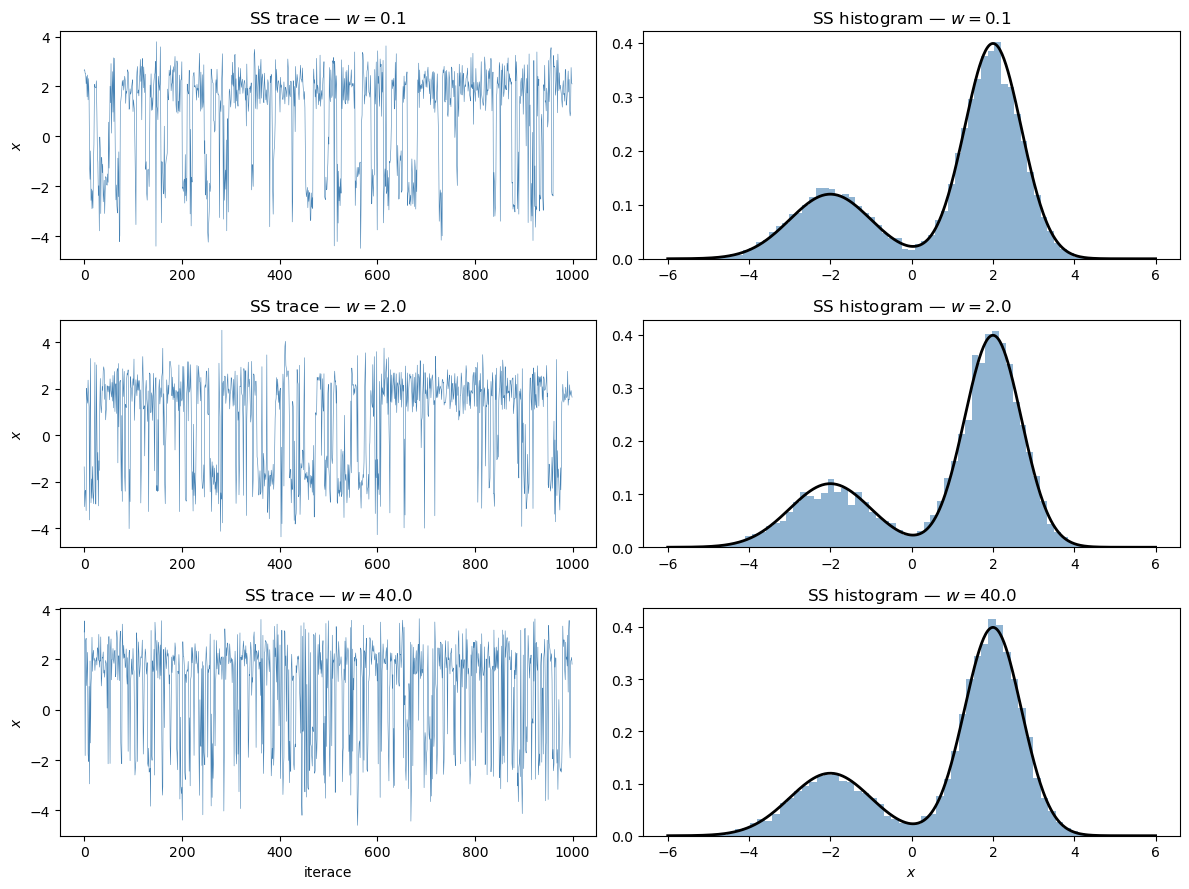

In [9]:
# --- Slice Sampling s různými w ---
ws = [0.1, 2.0, 40.0]
fig, axes = plt.subplots(len(ws), 2, figsize=(12, 3 * len(ws)))

for i, w in enumerate(ws):
    start_time = time.time()
    samples_w, n_evals_w = slice_sampling(log_target_pdf, x0=0.0, n_samples=N, w=w)
    elapsed = time.time() - start_time
    print(f"w = {w:5.1f} | vyhodnocení f(x): {n_evals_w:,} | čas: {elapsed:.3f} s")

    axes[i, 0].plot(samples_w[:1000], lw=0.4, color='steelblue')
    axes[i, 0].set_ylabel("$x$")
    axes[i, 0].set_title(f"SS trace — $w={w}$")

    axes[i, 1].hist(samples_w[1000:], bins=60, density=True, alpha=0.6, color='steelblue')
    axes[i, 1].plot(x_grid, target_pdf(x_grid), 'k-', lw=2)
    axes[i, 1].set_title(f"SS histogram — $w={w}$")

axes[-1, 0].set_xlabel("iterace"); axes[-1, 1].set_xlabel("$x$")
plt.tight_layout(); plt.show()

## Shrnutí

| Vlastnost | Metropolis-Hastings | Slice Sampling |
|---|---|---|
| Akceptační krok | Ano (když je návrh zamítnut, řetězec stojí) | Ne (každý vzorek je nový) |
| Klíčový parametr | $\sigma$ (proposal) — **velmi citlivý** | $w$ (šířka okna) — **málo citlivý** |
| Špatná volba parametru | Zhoršuje kvalitu vzorků | Zhoršuje rychlost vzorkování |
| Počet vyhodnocení $f(x)$ v každém kroce | 1 (ale mnohé zamítnuty) | Více (stepping-out + shrinking) |
| Robustnost | Nižší — vyžaduje pečlivé ladění | Vyšší — přizpůsobuje se tvaru rozdělení |

**Závěr:** Slice sampling je zajímavou alternativou k MH zejména tam, kde je ladění návrhového rozdělení obtížné — typicky u složitějších aposteriorních rozdělení v bayesovské inverzi.